In [1]:
import pandas as pd
print("Notebook works! pandas version:", pd.__version__)

Notebook works! pandas version: 2.2.3


# Calibrating Low-Cost Ozone Sensors with Machine Learning

**Module:** 6COSC017C Machine Learning and Data Analytics — Coursework 1 (2026–2027)
**Student ID:** 00018321

| Part | Content |
|---|---|
| A | Introduction and data loading |
| B | Exploratory Data Analysis |
| C | Data preparation and feature engineering |
| D | Model training and hyperparameter tuning |
| E | Model evaluation and final model selection |

## 1. Introduction

### 1.1 Scientific case
Ground-level ozone (O3) is a harmful air pollutant. Official monitoring stations measure it
accurately but are expensive, so cities have only a few of them. Low-cost IoT sensors could
fill the gaps, but their raw readings are inaccurate: they drift and react to temperature
and humidity.

**Research question:** can a machine-learning model, using only the readings of a cheap
sensor, predict the ozone value that the official station would measure?

### 1.2 Problem framing
- **Type:** supervised learning — **regression** (the target is a continuous number).
- **Target:** ozone measured by the official reference station (µg/m³).
- **Inputs:** readings from a low-cost sensor placed next to the station, plus time features.
- **Baseline to beat:** the raw low-cost ozone reading with no model.

### 1.3 Dataset origin and licence
Collected by researchers at the Universitat de València at the *Molí del Sol* official
station in Valencia, Spain, from 31 May 2024 to 23 January 2025 (238 days). Two low-cost
sensor nodes were placed next to the official station, so all three measured the same air.

- **Source:** Zenodo — https://doi.org/10.5281/zenodo.17044034
- **Licence:** CC BY 4.0 (free to use and adapt, with credit to the authors)
- **Related paper:** Montalbán-Faet et al. (2025), *Atmospheric Measurement Techniques*, 18, 4357.

In [2]:

# Core libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings: show all columns, round numbers to 3 decimals
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

# Fixed random seed so every result is reproducible
RANDOM_STATE = 42

# Folder with the raw data (relative to the notebooks/ folder)
DATA_DIR = Path("../data/raw")
print("Data files found:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Data files found: ['gva_10.csv', 'n1_10.csv', 'n2_10.csv']


## 2. Data Loading

### 2.1 Which files and why
The Zenodo archive contains 9 CSV files: **3 sources × 3 time resolutions** (10, 30 and 60 minutes).

| Source | File used | Description |
|---|---|---|
| Official reference station | `gva_10.csv` | Accurate "ground truth" measurements (the target) |
| Low-cost node 1 | `n1_10.csv` | Raw cheap-sensor readings (inputs) |
| Low-cost node 2 | `n2_10.csv` | Raw cheap-sensor readings (inputs) |

**Why only the 10-minute files:** the 30- and 60-minute files are averages of the same
measurements, so they add no new information. The 10-minute files keep the most rows
(about 3× and 6× more) and the most detail.

In [3]:
# Load each source into its own DataFrame
ref_raw = pd.read_csv(DATA_DIR / "gva_10.csv")   # official reference station
n1_raw  = pd.read_csv(DATA_DIR / "n1_10.csv")    # low-cost node 1
n2_raw  = pd.read_csv(DATA_DIR / "n2_10.csv")    # low-cost node 2

# Size of each file: (rows, columns)
print("Reference station:", ref_raw.shape)
print("Node 1:           ", n1_raw.shape)
print("Node 2:           ", n2_raw.shape)

Reference station: (34141, 17)
Node 1:            (34141, 12)
Node 2:            (34141, 12)


In [4]:
# Look at the first rows of each source
display(ref_raw.head())
display(n1_raw.head())
print("Node 1 and node 2 have the same columns:", n1_raw.columns.equals(n2_raw.columns))

,SO2,CO,O3,NOx,NO,NO2,PM10,"PM2,5",PM1,SPL,PM10_S/C,"PM2,5_S/C",Temp_Int,HR_Int,HR,PM1_S/C,rounded_datetime
0,4.740,0.030,58.000,26.000,1.000,25.000,4.000,4.000,2.000,79.000,4.000,4.000,24.000,53.000,2.000,220.700,1717141200000000000
1,4.370,0.030,61.000,25.000,1.000,23.000,4.000,4.000,1.000,79.000,4.000,4.000,24.100,52.000,1.000,221.800,1717141800000000000
2,4.520,0.030,63.000,22.000,1.000,21.000,5.000,4.000,2.000,78.000,5.000,4.000,24.100,52.000,2.000,220.400,1717142400000000000
3,4.700,0.030,59.000,23.000,1.000,22.000,5.000,5.000,2.000,78.000,5.000,5.000,24.200,52.000,2.000,218.200,1717143000000000000
4,4.320,0.030,59.000,23.000,1.000,22.000,4.000,4.000,2.000,78.000,4.000,4.000,24.300,52.000,2.000,218.900,1717143600000000000


,Temp,HR,PM1,PM2_5,PM10,VOC,CH2O,CO2,CO,O3,NO2,rounded_datetime
0,12.845,99.623,12.472,16.019,17.000,0.811,0.018,740.131,0.573,59.610,10.107,1717141200000000000
1,13.161,98.963,13.037,16.426,17.426,0.000,0.019,723.192,0.573,103.566,18.816,1717141800000000000
2,13.297,97.292,12.723,16.246,17.246,0.077,0.018,723.426,0.573,66.416,18.816,1717142400000000000
3,13.385,94.778,12.500,16.074,17.074,0.000,0.018,723.158,0.573,75.948,18.816,1717143000000000000
4,13.632,93.477,11.785,15.492,16.492,0.000,0.017,723.786,0.573,54.643,18.816,1717143600000000000


Node 1 and node 2 have the same columns: True


**Observations**
- All three files have the same number of rows, suggesting they share the same timestamps.
- Time is stored in `rounded_datetime` as a **Unix timestamp in nanoseconds**, which is not
  readable and must be converted to a date.
- Several names (`O3`, `CO`, `PM10`, `HR`) appear in more than one file, so each column gets
  a prefix showing its source: `ref_`, `n1_` or `n2_`.
- The reference file uses commas and slashes in names (`PM2,5`, `PM10_S/C`); these are
  standardised to underscores.

### 2.2 Convert and check timestamps
Before joining, we check the timestamp is a valid join key in each file:
1. **No duplicates**: otherwise the join would multiply rows.
2. **Regular 10-minute steps**: gaps would affect time-based features later.

In [5]:
def prepare_source(df, prefix):
    """Convert the timestamp to a date and add a source prefix to every other column."""
    out = df.copy()
    out["datetime"] = pd.to_datetime(out.pop("rounded_datetime"), unit="ns")
    out.columns = [c if c == "datetime"
                   else prefix + c.replace(",", "_").replace("/", "_")
                   for c in out.columns]
    return out.sort_values("datetime").reset_index(drop=True)

ref = prepare_source(ref_raw, "ref_")
n1  = prepare_source(n1_raw,  "n1_")
n2  = prepare_source(n2_raw,  "n2_")

# Check each source: date range, duplicate timestamps, size of time steps
for name, df_ in [("Reference", ref), ("Node 1", n1), ("Node 2", n2)]:
    steps = df_["datetime"].diff().dropna().value_counts()
    print(f"{name:10s} | {df_['datetime'].min()} -> {df_['datetime'].max()} "
          f"| duplicates: {df_['datetime'].duplicated().sum()} "
          f"| time steps: {steps.to_dict()}")

# How many 10-minute slots should exist in this period?
expected = int((ref["datetime"].max() - ref["datetime"].min()) / pd.Timedelta("10min")) + 1
print(f"\nExpected 10-minute slots: {expected:,} | rows in each file: {len(ref):,}")

Reference  | 2024-05-31 07:40:00 -> 2025-01-23 09:40:00 | duplicates: 0 | time steps: {Timedelta('0 days 00:10:00'): 34140}
Node 1     | 2024-05-31 07:40:00 -> 2025-01-23 09:40:00 | duplicates: 0 | time steps: {Timedelta('0 days 00:10:00'): 34140}
Node 2     | 2024-05-31 07:40:00 -> 2025-01-23 09:40:00 | duplicates: 0 | time steps: {Timedelta('0 days 00:10:00'): 34140}

Expected 10-minute slots: 34,141 | rows in each file: 34,141


**Result:** each file covers the same period, has no duplicate timestamps and a perfectly
regular 10-minute step with **no missing time slots**.

A perfect grid over 238 days of real sensor operation is unusual, because sensors normally
have outages. This suggests the publishers may have **filled gaps** before release. We will
look for evidence (such as long runs of identical values) in the EDA.

### 2.3 Join the three sources
**Method:** an **inner join** on `datetime` using `pd.merge` (Seminar 3; Lecture 3, *Data Integration*).

**Justification**
- `datetime` is the only column the three sources share, and it uniquely identifies each
  10-minute measurement, so it is the natural join key.
- An **inner** join keeps only timestamps present in all three sources, so every row has
  both the inputs and the target.
- `validate="one_to_one"` makes pandas raise an error if any timestamp were duplicated,
  instead of silently creating extra rows.
- Following Lecture 3's advice to *check row counts after every join*, we assert that no
  rows were lost or created.

In [6]:
# Join 1: reference station + node 1
merged = pd.merge(ref, n1, on="datetime", how="inner", validate="one_to_one")
assert len(merged) == len(ref) == len(n1), "Row count changed after joining node 1"

# Join 2: result + node 2
df = pd.merge(merged, n2, on="datetime", how="inner", validate="one_to_one")
assert len(df) == len(ref) == len(n2), "Row count changed after joining node 2"

# Use the timestamp as the index (standard for time-series data)
df = df.set_index("datetime")

print(f"Joined dataset shape: {df.shape}")
print(f"Rows before join: {len(ref):,} | rows after join: {len(df):,} -> no rows lost or duplicated")
df.head()

Joined dataset shape: (34141, 38)
Rows before join: 34,141 | rows after join: 34,141 -> no rows lost or duplicated


,ref_SO2,ref_CO,ref_O3,ref_NOx,ref_NO,ref_NO2,ref_PM10,ref_PM2_5,ref_PM1,ref_SPL,ref_PM10_S_C,ref_PM2_5_S_C,ref_Temp_Int,ref_HR_Int,ref_HR,ref_PM1_S_C,n1_Temp,n1_HR,n1_PM1,n1_PM2_5,n1_PM10,n1_VOC,n1_CH2O,n1_CO2,n1_CO,n1_O3,n1_NO2,n2_Temp,n2_HR,n2_PM1,n2_PM2_5,n2_PM10,n2_VOC,n2_CH2O,n2_CO2,n2_CO,n2_O3,n2_NO2
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-05-31 07:40:00,4.740,0.030,58.000,26.000,1.000,25.000,4.000,4.000,2.000,79.000,4.000,4.000,24.000,53.000,2.000,220.700,12.845,99.623,12.472,16.019,17.000,0.811,0.018,740.131,0.573,59.610,10.107,12.845,99.623,12.472,16.019,17.000,0.811,0.018,740.131,0.573,59.610,10.107
2024-05-31 07:50:00,4.370,0.030,61.000,25.000,1.000,23.000,4.000,4.000,1.000,79.000,4.000,4.000,24.100,52.000,1.000,221.800,13.161,98.963,13.037,16.426,17.426,0.000,0.019,723.192,0.573,103.566,18.816,13.161,98.963,13.037,16.426,17.426,0.000,0.019,723.192,0.573,103.566,18.816
2024-05-31 08:00:00,4.520,0.030,63.000,22.000,1.000,21.000,5.000,4.000,2.000,78.000,5.000,4.000,24.100,52.000,2.000,220.400,13.297,97.292,12.723,16.246,17.246,0.077,0.018,723.426,0.573,66.416,18.816,13.297,97.292,12.723,16.246,17.246,0.077,0.018,723.426,0.573,66.416,18.816
2024-05-31 08:10:00,4.700,0.030,59.000,23.000,1.000,22.000,5.000,5.000,2.000,78.000,5.000,5.000,24.200,52.000,2.000,218.200,13.385,94.778,12.500,16.074,17.074,0.000,0.018,723.158,0.573,75.948,18.816,13.385,94.778,12.500,16.074,17.074,0.000,0.018,723.158,0.573,75.948,18.816
2024-05-31 08:20:00,4.320,0.030,59.000,23.000,1.000,22.000,4.000,4.000,2.000,78.000,4.000,4.000,24.300,52.000,2.000,218.900,13.632,93.477,11.785,15.492,16.492,0.000,0.017,723.786,0.573,54.643,18.816,13.632,93.477,11.785,15.492,16.492,0.000,0.017,723.786,0.573,54.643,18.816


In [7]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34141 entries, 2024-05-31 07:40:00 to 2025-01-23 09:40:00
Data columns (total 38 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ref_SO2        34141 non-null  float64
 1   ref_CO         34141 non-null  float64
 2   ref_O3         34141 non-null  float64
 3   ref_NOx        34141 non-null  float64
 4   ref_NO         34141 non-null  float64
 5   ref_NO2        34141 non-null  float64
 6   ref_PM10       34141 non-null  float64
 7   ref_PM2_5      34141 non-null  float64
 8   ref_PM1        34141 non-null  float64
 9   ref_SPL        34141 non-null  float64
 10  ref_PM10_S_C   34141 non-null  float64
 11  ref_PM2_5_S_C  34141 non-null  float64
 12  ref_Temp_Int   34141 non-null  float64
 13  ref_HR_Int     34141 non-null  float64
 14  ref_HR         34141 non-null  float64
 15  ref_PM1_S_C    34141 non-null  float64
 16  n1_Temp        34141 non-null  float64
 17  n1_HR          

### 2.4 Summary of Part A
| Item | Value |
|---|---|
| Sources joined | 3 (reference station + 2 low-cost nodes) |
| Join key | `datetime` (10-minute timestamps) |
| Rows | 34,141 |
| Columns | 38 (16 reference + 11 node 1 + 11 node 2) |
| Period | 31 May 2024 – 23 January 2025 |
| Target variable | `ref_O3` (ozone at the official station) |

**Next (Part B, EDA):** summary statistics, distributions, correlations and data-quality checks.

# Part B — Exploratory Data Analysis

## 3. EDA

### 3.1 Summary statistics
Following Lecture 2, we compute measures of **central tendency** (mean, median) and
**dispersion** (standard deviation, variance) for every column, plus **skewness** to check
the shape of each distribution (|skew| > 1 = highly skewed, 0.5–1 = moderately skewed).

In [8]:
# Summary statistics for all 38 columns
stats = df.describe().T                 # count, mean, std, min, quartiles, max
stats["variance"] = df.var()            # variance = std squared
stats["skewness"] = df.skew()           # shape of the distribution
stats[["mean", "50%", "std", "variance", "min", "max", "skewness"]]

,mean,50%,std,variance,min,max,skewness
ref_SO2,4.230,3.570,3.384,11.449,-151.230,196.000,5.598
ref_CO,0.077,0.040,0.249,0.062,-0.010,3.890,9.934
ref_O3,61.442,52.000,859.888,"739,407.802",0.000,"97,336.000",95.290
ref_NOx,18.421,11.000,"4,796.718","23,008,507.735","-531,441.000","194,481.000",-73.184
ref_NO,4.327,2.000,31.403,986.174,-462.250,"3,375.000",50.971
ref_NO2,10.809,9.000,118.450,"14,030.465","-13,122.000","1,521.000",-85.087
ref_PM10,15.460,8.000,258.698,"66,924.845",0.000,"39,204.167",122.291
ref_PM2_5,9.646,6.100,14.808,219.277,0.000,"1,280.000",29.015
ref_PM1,6.688,5.000,7.839,61.443,0.000,163.840,5.102
ref_SPL,67.213,71.000,12.665,160.411,24.000,108.457,-0.740


In [9]:
# Focus on the target: compare mean, trimmed mean and median (Lecture 2)
from scipy.stats import trim_mean

target = df["ref_O3"]
print(f"Mean:             {target.mean():.2f}")
print(f"5% trimmed mean:  {trim_mean(target, 0.05):.2f}")
print(f"Median:           {target.median():.2f}")
print(f"Std:              {target.std():.2f}")
print(f"Max:              {target.max():,.0f}")

Mean:             61.44
5% trimmed mean:  48.93
Median:           52.00
Std:              859.89
Max:              97,336


**Observations**
- **The target `ref_O3` has impossible values.** Its median is 52 µg/m³ but its maximum is
  97,336 and its standard deviation (≈860) is far larger than its mean. A few extreme errors
  are inflating the mean and standard deviation. The trimmed mean and median, which ignore
  extremes (Lecture 2), give a realistic central value.
- **Other reference pollutants have impossible negative values**: `ref_NOx` down to −531,441,
  `ref_NO2` down to −13,122, `ref_SO2` down to −151. Concentrations cannot be negative.
- **Duplicated columns:** `ref_HR` has exactly the same statistics as `ref_PM1`, and
  `ref_PM10_S_C` matches `ref_PM10`. They will be checked directly in Section 3.3.
- **Suspicious low-cost sensors:** `n1_CO` and `n2_CO` barely vary (std ≈ 0.004), and
  `n1_NO2` has a maximum equal to its median (18.816), which suggests a stuck sensor.
- **Most columns are highly skewed** (|skew| > 1), so the median and IQR describe them better
  than the mean and std, and Spearman correlation will be more reliable than Pearson.

### 3.2 Distribution of the target (`ref_O3`)
We use three plots from Lecture 2:
- **Box plot** of all values, to show outliers;
- **Histogram** of the plausible range (≤ 300 µg/m³), to show the real shape, because the
  extreme errors squash everything else into one bar;
- **Q-Q plot**, to compare the distribution with a normal distribution.

Outliers are counted with the **IQR rule** (Lecture 3): values above Q3 + 1.5 × IQR.

Q1 = 29, Q3 = 69, IQR = 40, upper fence = 129
Values above the IQR fence: 151
Values above 300 µg/m³:     62
Values equal to 0:          494


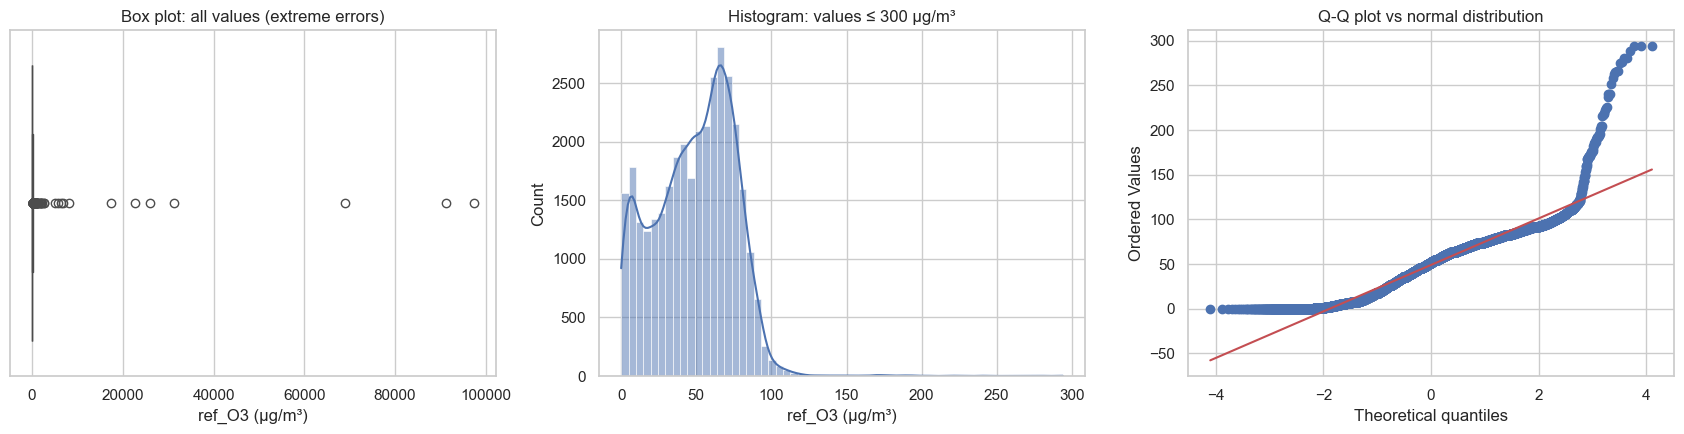

In [10]:
from scipy import stats as st

target = df["ref_O3"]

# IQR rule for outliers
q1, q3 = target.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}, upper fence = {upper_fence:.0f}")
print(f"Values above the IQR fence: {(target > upper_fence).sum()}")
print(f"Values above 300 µg/m³:     {(target > 300).sum()}")
print(f"Values equal to 0:          {(target == 0).sum()}")

# Three plots side by side
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(x=target, ax=axes[0])
axes[0].set_title("Box plot: all values (extreme errors)")
axes[0].set_xlabel("ref_O3 (µg/m³)")

plausible = target[target <= 300]
sns.histplot(plausible, bins=60, kde=True, ax=axes[1])
axes[1].set_title("Histogram: values ≤ 300 µg/m³")
axes[1].set_xlabel("ref_O3 (µg/m³)")

st.probplot(plausible, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot vs normal distribution")

plt.tight_layout()
plt.show()

**Observations**
- **Extreme errors:** 62 values exceed 300 µg/m³ (up to 97,336). Real ozone in Europe
  rarely exceeds ~240 µg/m³, so these are measurement or recording errors, not real events.
- **IQR rule:** 151 values lie above the upper fence (129 µg/m³). Not all of them are
  necessarily errors, so the cleaning threshold will be decided in Part C.
- **Shape of the plausible values:** two peaks, one near 0–10 µg/m³ and a larger one near
  70 µg/m³. This suggests a **daily cycle**: ozone forms in sunlight during the day and
  drops at night. This is checked in Section 3.4.
- **494 exact zeros:** these may be real night-time minimums or a sensor floor, also checked
  in Section 3.4.
- **Not normal:** the Q-Q plot bends away from the line at both ends, so the target is not
  normally distributed. This favours robust statistics (median, IQR) and **Spearman**
  correlation, and models that do not assume normality (e.g. tree-based models).

### 3.3 Data-quality checks
Five checks, based on the problems hinted at in the summary statistics:
1. Impossible values (negative concentrations, ozone above 300, humidity above 100%)
2. Duplicated columns
3. Stuck or near-constant sensors
4. The low-cost ozone sensor's minimum value (detection floor)
5. Copied data between the two low-cost nodes

In [11]:
# 1. Impossible values: concentrations can't be negative; humidity can't exceed 100 %
checks = {}
for col in ["ref_SO2", "ref_CO", "ref_O3", "ref_NOx", "ref_NO", "ref_NO2", "ref_PM10", "ref_PM2_5"]:
    checks[f"{col} < 0"] = (df[col] < 0).sum()
checks["ref_O3 > 300"] = (df["ref_O3"] > 300).sum()
for col in ["n1_HR", "n2_HR", "ref_HR_Int"]:
    checks[f"{col} > 100 %"] = (df[col] > 100).sum()

impossible = pd.Series(checks, name="rows").to_frame()
impossible["% of rows"] = (impossible["rows"] / len(df) * 100).round(2)
impossible

,rows,% of rows
ref_SO2 < 0,813,2.380
ref_CO < 0,1231,3.610
ref_O3 < 0,0,0.000
ref_NOx < 0,1123,3.290
ref_NO < 0,1385,4.060
ref_NO2 < 0,1227,3.590
ref_PM10 < 0,0,0.000
ref_PM2_5 < 0,0,0.000
ref_O3 > 300,62,0.180
n1_HR > 100 %,15904,46.580


In [12]:
# 2. Duplicated columns: find every pair of columns with identical values
cols = df.columns
duplicates = [(a, b) for i, a in enumerate(cols) for b in cols[i+1:] if df[a].equals(df[b])]
print("Identical column pairs:", duplicates)

# 3. Stuck sensors: how often does each sensor report its single most common value?
print("\nShare of rows equal to the most common value:")
for col in ["n1_NO2", "n2_NO2", "n1_CO", "n2_CO", "n1_VOC", "n2_VOC"]:
    mode = df[col].mode()[0]
    share = (df[col] == mode).mean() * 100
    print(f"  {col:7s} value {mode:7.3f} -> {share:5.1f} % of rows")

Identical column pairs: [('ref_PM10', 'ref_PM10_S_C'), ('ref_PM1', 'ref_HR')]

Share of rows equal to the most common value:
  n1_NO2  value  18.816 ->  99.0 % of rows
  n2_NO2  value  18.816 ->  58.0 % of rows
  n1_CO   value   0.573 -> 100.0 % of rows
  n2_CO   value   0.573 -> 100.0 % of rows
  n1_VOC  value   0.000 ->  92.5 % of rows
  n2_VOC  value   0.000 ->  93.3 % of rows


n1: 30.6 % of rows at 39.246 | real ozone median when at floor: 23 vs otherwise: 61
n2: 60.6 % of rows at 39.246 | real ozone median when at floor: 38 vs otherwise: 68


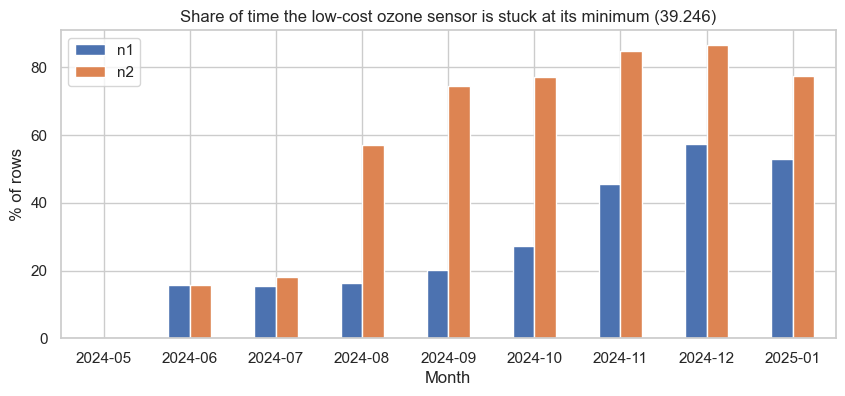

In [13]:
# 4. The low-cost ozone sensors often report exactly 39.246 (their minimum)
FLOOR = 39.246
for node in ["n1", "n2"]:
    at_floor = df[f"{node}_O3"].round(3) == FLOOR
    print(f"{node}: {at_floor.mean()*100:.1f} % of rows at {FLOOR} | "
          f"real ozone median when at floor: {df.loc[at_floor & (df.ref_O3 <= 300), 'ref_O3'].median():.0f} "
          f"vs otherwise: {df.loc[~at_floor & (df.ref_O3 <= 300), 'ref_O3'].median():.0f}")

# When does it happen? Share of rows at the floor, by month
floor_by_month = pd.DataFrame({
    node: (df[f"{node}_O3"].round(3) == FLOOR).groupby(df.index.to_period("M")).mean() * 100
    for node in ["n1", "n2"]})
floor_by_month.plot(kind="bar", figsize=(10, 4))
plt.title("Share of time the low-cost ozone sensor is stuck at its minimum (39.246)")
plt.ylabel("% of rows")
plt.xlabel("Month")
plt.xticks(rotation=0)
plt.show()

In [14]:
# 5. Are node 1 and node 2 identical? (they should be two independent sensors)
n1_cols = [c for c in df.columns if c.startswith("n1_")]
n2_cols = [c.replace("n1_", "n2_") for c in n1_cols]
identical_rows = (df[n1_cols].values.round(6) == df[n2_cols].values.round(6)).all(axis=1)

(pd.Series(identical_rows, index=df.index)
   .groupby(df.index.to_period("M")).mean().mul(100).round(1)
   .rename("% of rows where node 1 = node 2"))

datetime
2024-05   100.000
2024-06   100.000
2024-07    92.000
2024-08     0.000
2024-09     0.000
2024-10     0.000
2024-11     0.000
2024-12     0.000
2025-01     0.000
Freq: M, Name: % of rows where node 1 = node 2, dtype: float64

**Observations and decisions for Part C**

| Problem found | Evidence | Decision |
|---|---|---|
| Negative pollutant values | 2–4 % of rows in SO2, CO, NOx, NO, NO2 | Physically impossible. These reference columns are **not model inputs** (see below), so they need no correction. |
| Target errors | 62 rows with `ref_O3` > 300 µg/m³ | Treat as missing and **remove those rows**: a model cannot learn from a wrong target. |
| Humidity above 100 % | ~50 % of rows in both nodes | A consistent calibration offset of the cheap humidity sensor, not random errors. Keep it: correcting this kind of bias is exactly what the model learns. |
| Duplicated columns | `ref_HR` = `ref_PM1`; `ref_PM10_S_C` = `ref_PM10` | Mislabelled copies; not used. |
| Stuck sensors | `n1_NO2` 99 % one value; both `CO` ~100 %; VOC ~93 % zero | **Drop** NO2 and CO: they carry no information. VOC to be reviewed. |
| Ozone sensor floor | n1 at 39.246 in 31 % of rows, n2 in 61 %; mostly winter and night; real ozone is low at these times | The cheap sensor cannot measure low ozone. Keep it, and add a **"sensor at floor" flag** as a feature. |
| Copied node data | Node 1 = node 2 in 100 % of rows in May–June and 92 % in July | Node 2 was a copy of node 1 early on, and its ozone floor is hit far more often. **Use node 1 as the main input**; node 2 is kept for comparison. |

**Important: no reference-station inputs.** In real use, a calibrated cheap sensor works
*without* an official station next to it. So only low-cost sensor readings and time features
can be inputs. Using `ref_NO2` or other reference columns would be **data leakage**.

### 3.4 Time patterns
Two views of ozone over time (plausible values only, ≤ 300 µg/m³):
- **Daily averages** across the whole period, to see seasonal trends and how closely each
  low-cost sensor follows the official station;
- **Median by hour of day**, to see the daily cycle.

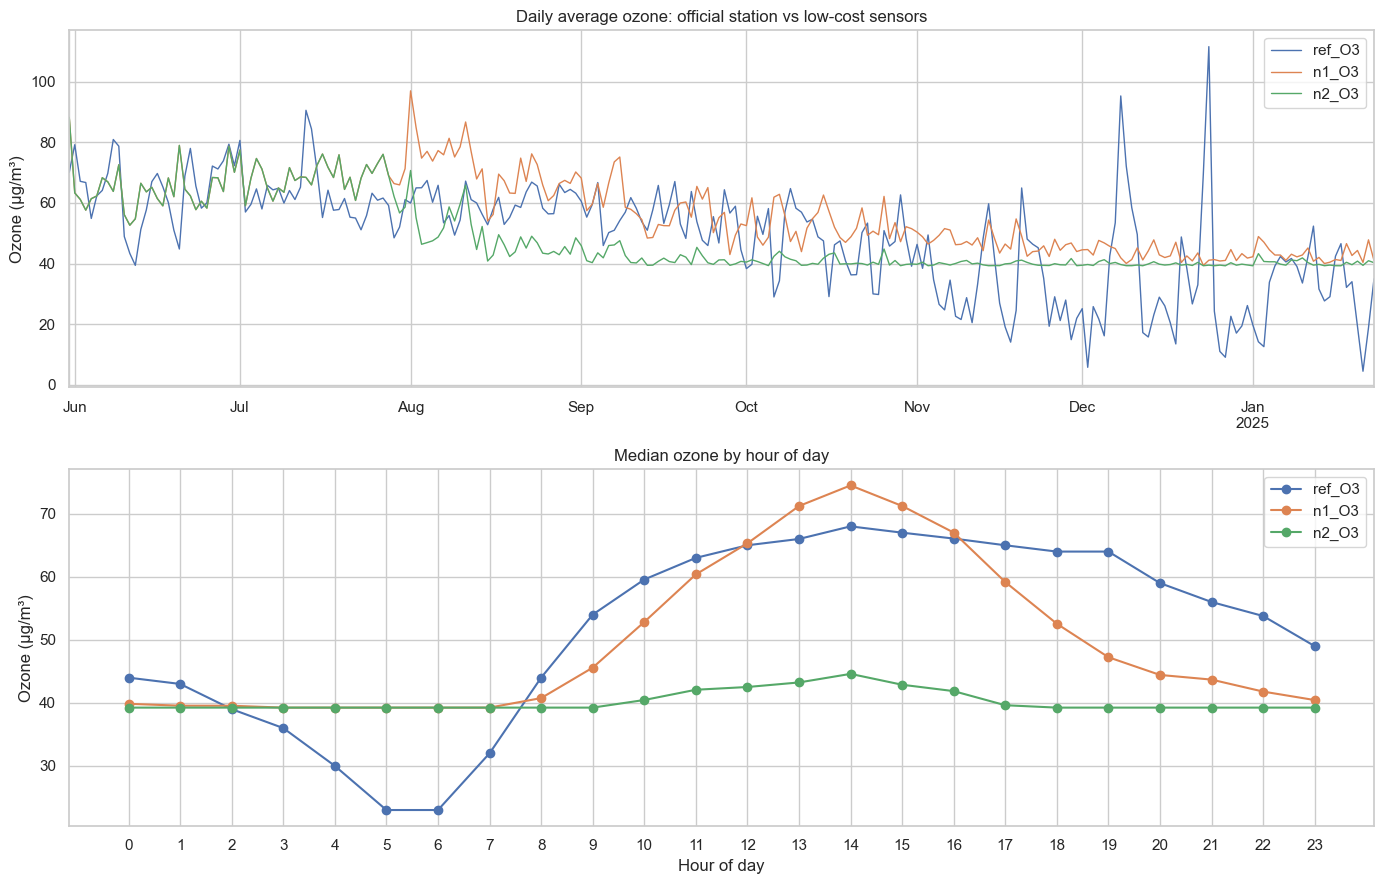

In [15]:
valid = df[df["ref_O3"] <= 300]          # exclude the target errors for plotting
o3_cols = ["ref_O3", "n1_O3", "n2_O3"]

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# 1. Daily averages over the whole period
valid[o3_cols].resample("D").mean().plot(ax=axes[0], linewidth=1)
axes[0].set_title("Daily average ozone: official station vs low-cost sensors")
axes[0].set_ylabel("Ozone (µg/m³)")
axes[0].set_xlabel("")

# 2. Median by hour of day
hourly = valid[o3_cols].groupby(valid.index.hour).median()
hourly.plot(ax=axes[1], marker="o")
axes[1].set_title("Median ozone by hour of day")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Ozone (µg/m³)")
axes[1].set_xticks(range(24))

plt.tight_layout()
plt.show()

In [16]:
# Monthly median of real ozone, and when the 494 zeros happen
print("Monthly median of ref_O3:")
print(valid["ref_O3"].groupby(valid.index.to_period("M")).median().round(0).to_string())

zeros = df["ref_O3"] == 0
print("\nZeros by month:", zeros.groupby(df.index.to_period("M")).sum()[lambda s: s > 0].to_dict())
print("Zeros by hour: ", zeros.groupby(df.index.hour).sum().to_dict())

Monthly median of ref_O3:
datetime
2024-05   70.000
2024-06   69.000
2024-07   67.000
2024-08   65.000
2024-09   59.000
2024-10   50.000
2024-11   31.000
2024-12   28.000
2025-01   35.000
Freq: M

Zeros by month: {Period('2024-11', 'M'): 1, Period('2024-12', 'M'): 289, Period('2025-01', 'M'): 204}
Zeros by hour:  {0: 17, 1: 14, 2: 12, 3: 14, 4: 14, 5: 25, 6: 42, 7: 41, 8: 15, 9: 6, 10: 6, 11: 1, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 4, 18: 33, 19: 60, 20: 70, 21: 56, 22: 35, 23: 29}


**Observations**
- **Seasonal trend:** real ozone falls from a monthly median of ~70 µg/m³ in summer to ~30 in
  December, as ozone forms in sunlight and winter has less of it.
- **Daily cycle:** real ozone is lowest at 5–6 am (~23) and highest at ~2 pm (~68). This
  explains the two peaks in the histogram (Section 3.2).
- **Node 1 follows the daytime pattern but not the night:** at night it stays at its floor
  (~39) while real ozone keeps falling. So it **overestimates at night and in winter**.
- **Node 2 is almost useless for ozone after August:** its line is nearly flat at ~40, which
  confirms the floor problem in Section 3.3. Node 1 is used as the main input.
- **The 494 zeros are plausible:** they occur only in December–January evenings and early
  mornings, when ozone is naturally lowest (traffic emissions destroy ozone after sunset).
  They are kept as real values.

**Implications for modelling**
1. **Hour of day** and **month** are useful features: the error of the cheap sensor depends
   on both.
2. The data **changes over the seasons**, so the test set must cover all seasons. A model
   tested only on winter but trained on summer would fail. This supports a **week-blocked
   split** (Part C).
3. Rows 10 minutes apart are almost identical, so a **random split would leak** information
   between training and test sets.

### 3.5 Correlations
We compare two correlation measures (Lecture 2):
- **Pearson**: measures *linear* relationships and is sensitive to outliers;
- **Spearman**: uses ranks, so it captures any *monotonic* relationship and is robust to outliers.

Inputs: node 1 sensor readings (without the stuck NO2 and CO sensors) and hour of day.
Only rows with a plausible target (≤ 300 µg/m³) are used.

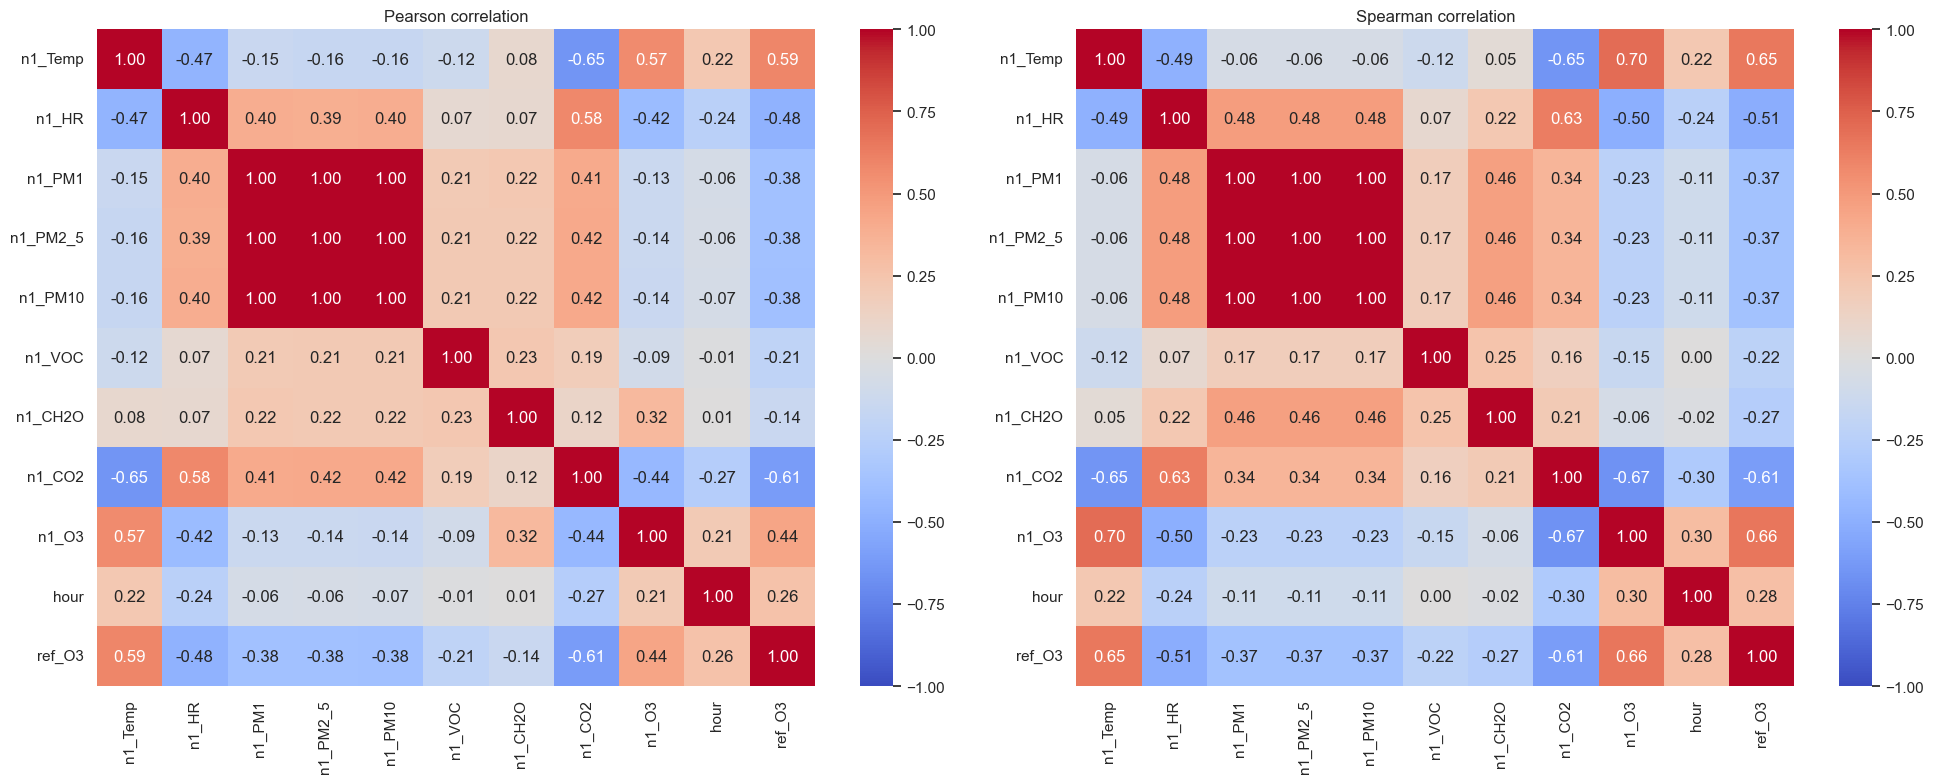

In [17]:
valid = df[df["ref_O3"] <= 300].copy()
valid["hour"] = valid.index.hour

corr_cols = ["n1_Temp", "n1_HR", "n1_PM1", "n1_PM2_5", "n1_PM10",
             "n1_VOC", "n1_CH2O", "n1_CO2", "n1_O3", "hour", "ref_O3"]

pearson = valid[corr_cols].corr(method="pearson")
spearman = valid[corr_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout()
plt.show()

In [18]:
# Correlation of each input with the target, sorted by strength
(pd.DataFrame({"Pearson": pearson["ref_O3"], "Spearman": spearman["ref_O3"]})
   .drop("ref_O3")
   .round(2)
   .sort_values("Spearman", key=abs, ascending=False))

,Pearson,Spearman
n1_O3,0.440,0.660
n1_Temp,0.590,0.650
n1_CO2,-0.610,-0.610
n1_HR,-0.480,-0.510
n1_PM1,-0.380,-0.370
n1_PM2_5,-0.380,-0.370
n1_PM10,-0.380,-0.370
hour,0.260,0.280
n1_CH2O,-0.140,-0.270
n1_VOC,-0.210,-0.220


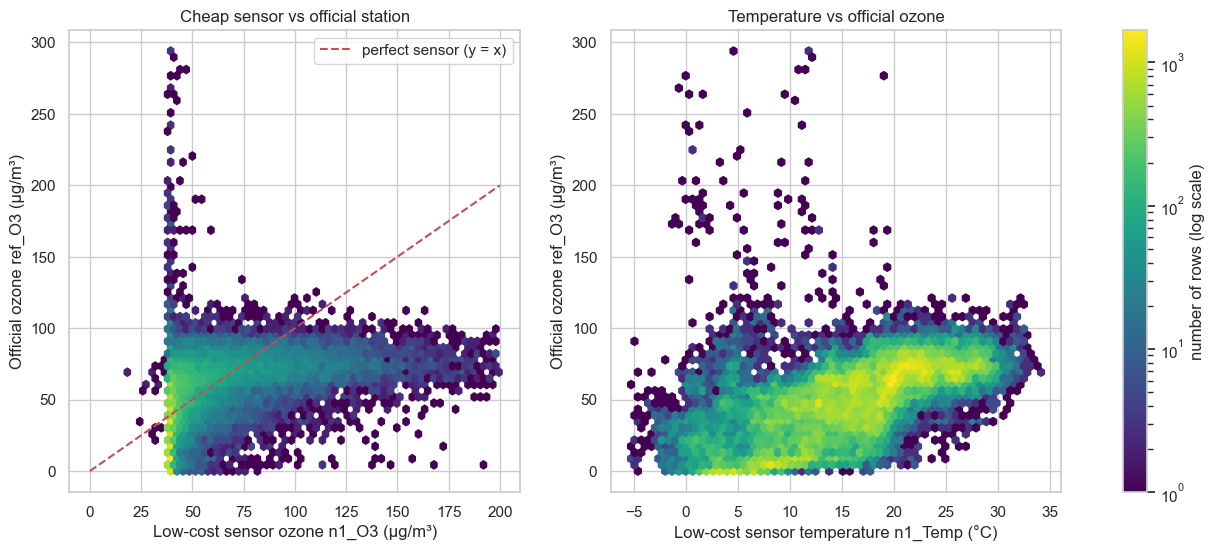

Rows where n1_O3 > 200 (sensor spikes): 119


In [19]:
# Hexbin plots: like scatter plots, but colour shows how many points fall in each cell
# (34,000 points would hide each other in a normal scatter plot)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

subset = valid[valid["n1_O3"] <= 200]
hb = axes[0].hexbin(subset["n1_O3"], subset["ref_O3"], gridsize=60, bins="log", cmap="viridis")
axes[0].plot([0, 200], [0, 200], "r--", label="perfect sensor (y = x)")
axes[0].set_xlabel("Low-cost sensor ozone n1_O3 (µg/m³)")
axes[0].set_ylabel("Official ozone ref_O3 (µg/m³)")
axes[0].set_title("Cheap sensor vs official station")
axes[0].legend()

axes[1].hexbin(valid["n1_Temp"], valid["ref_O3"], gridsize=60, bins="log", cmap="viridis")
axes[1].set_xlabel("Low-cost sensor temperature n1_Temp (°C)")
axes[1].set_ylabel("Official ozone ref_O3 (µg/m³)")
axes[1].set_title("Temperature vs official ozone")

plt.colorbar(hb, ax=axes, label="number of rows (log scale)")
plt.show()

print("Rows where n1_O3 > 200 (sensor spikes):", (valid["n1_O3"] > 200).sum())

**Observations**
- **Pearson vs Spearman for the raw sensor:** `n1_O3` has Pearson 0.44 but Spearman 0.66. The
  difference is caused by outliers (sensor spikes up to ~975) and the non-linear floor effect,
  which is exactly the situation where Lecture 2 recommends Spearman.
- **The raw sensor alone is a poor estimate:** in the hexbin plot most points are far from the
  "perfect sensor" line. The vertical band at ~39 shows the floor: when the sensor reads 39,
  real ozone can be anywhere from 0 to 100.
- **Other inputs carry useful information:** temperature (+0.65), CO2 (−0.61) and humidity
  (−0.51) are about as strongly related to ozone as the ozone sensor itself, because ozone
  depends on sunlight, heat and air mixing. A model that combines all of them should beat the
  raw sensor.
- **Multicollinearity:** `n1_PM1`, `n1_PM2_5` and `n1_PM10` are almost perfectly correlated
  (~1.00), so they carry the same information. Keeping one is enough, especially for linear
  models, whose coefficients become unstable with collinear inputs.
- **Hour of day is weakly correlated (0.27)** even though Section 3.4 shows a strong daily
  cycle. Correlation misses it because the cycle is **circular**: hour 23 is next to hour 0.
  In Part C, hour will be encoded with sine and cosine so models can use it.
- **Sensor spikes:** 119 rows have `n1_O3` > 200, which is physically unlikely; these input
  outliers will be handled in Part C.

### 3.6 Summary of the EDA

| # | Finding | Evidence | Action in Part C |
|---|---|---|---|
| 1 | The target has extreme errors | 62 rows with `ref_O3` > 300 (max 97,336); mean and std inflated | Remove these rows |
| 2 | The target is skewed and not normal | Two peaks; Q-Q plot bends at both ends | Use robust metrics (MAE alongside RMSE); include tree-based models |
| 3 | Stuck sensors carry no information | `n1_NO2` 99 % one value; `CO` ~100 % one value | Drop NO2 and CO |
| 4 | The ozone sensor has a floor at 39.246 | n1 at floor 31 % of rows; real ozone is low at those times | Add a binary "at floor" feature |
| 5 | Node 2 is unreliable | Copy of node 1 in May–July; flat ozone after August | Use node 1 as the main input |
| 6 | Strong daily and seasonal cycles | Real ozone ~23 at 5 am vs ~68 at 2 pm; ~70 in summer vs ~30 in winter | Add hour (sine/cosine) and month features |
| 7 | Hour of day is circular | Correlation 0.27 despite a clear cycle | Sine and cosine encoding |
| 8 | PM1, PM2.5 and PM10 are duplicates in practice | Correlation ~1.00 | Keep only PM2.5 |
| 9 | Low-cost ozone spikes | 119 rows with `n1_O3` > 200 | Cap extreme input values |
| 10 | Rows 10 minutes apart are near-identical; data shifts by season | Time-series plots | **Week-blocked** train/test split, not random |
| 11 | Reference-station readings would not exist in real use | Project goal: replace the expensive station | Use only low-cost sensor and time inputs (avoid leakage) |

**Baseline to beat:** using the raw `n1_O3` reading directly. Its Spearman correlation with the
real ozone is only 0.66, and it fails badly at night and in winter.

# Part C — Data Preparation

## 4. Data preparation
Each action below comes from the EDA summary (Section 3.6).

### 4.1 Cleaning
1. **Remove target errors:** rows with `ref_O3` > 300 µg/m³ (finding 1). A model cannot learn
   from a wrong target, so these rows are removed rather than corrected.
2. **Select inputs:** node 1 only (finding 5). Drop the stuck NO2 and CO sensors (finding 3),
   and keep only PM2.5 of the three near-identical PM columns (finding 8). No reference-station
   columns are used as inputs (finding 11).
3. **Mark impossible input values as missing:** low-cost ozone readings above 200 µg/m³
   (finding 9) are sensor spikes. They are set to missing (`NaN`) and filled later by the
   imputer, which learns its fill value from the training data only.

In [20]:
TARGET = "ref_O3"
INPUTS = ["n1_Temp", "n1_HR", "n1_PM2_5", "n1_VOC", "n1_CH2O", "n1_CO2", "n1_O3"]

# 1. Remove rows with an impossible target; 2. keep only the selected columns
rows_before = len(df)
data = df.loc[df[TARGET] <= 300, INPUTS + [TARGET]].copy()
print(f"Rows before: {rows_before:,} | removed (target > 300): {rows_before - len(data):,} "
      f"| rows kept: {len(data):,}")

# 3. Low-cost ozone spikes above 200 become missing values
data.loc[data["n1_O3"] > 200, "n1_O3"] = np.nan
print("\nMissing values per column after cleaning:")
print(data.isna().sum())

Rows before: 34,141 | removed (target > 300): 62 | rows kept: 34,079

Missing values per column after cleaning:
n1_Temp       0
n1_HR         0
n1_PM2_5      0
n1_VOC        0
n1_CH2O       0
n1_CO2        0
n1_O3       119
ref_O3        0
dtype: int64


### 4.2 Feature engineering
1. **`o3_at_floor`** (finding 4): 1 when the cheap sensor shows its minimum (39.246), else 0.
   This tells the model "the sensor reading is unreliable now; real ozone may be much lower".
2. **`hour_sin` and `hour_cos`** (findings 6–7): hour of day placed on a circle, so that
   23:00 and 00:00 are close together. A plain hour number (0–23) would put them far apart.

In [21]:
FLOOR = 39.246

# 1. Floor flag
data["o3_at_floor"] = (data["n1_O3"].round(3) == FLOOR).astype(int)

# 2. Hour of day on a circle (24-hour period)
hour = data.index.hour
data["hour_sin"] = np.sin(2 * np.pi * hour / 24)
data["hour_cos"] = np.cos(2 * np.pi * hour / 24)

FEATURES = INPUTS + ["o3_at_floor", "hour_sin", "hour_cos"]
print(f"{len(FEATURES)} model features:", FEATURES)
data.head()

10 model features: ['n1_Temp', 'n1_HR', 'n1_PM2_5', 'n1_VOC', 'n1_CH2O', 'n1_CO2', 'n1_O3', 'o3_at_floor', 'hour_sin', 'hour_cos']


,n1_Temp,n1_HR,n1_PM2_5,n1_VOC,n1_CH2O,n1_CO2,n1_O3,ref_O3,o3_at_floor,hour_sin,hour_cos
datetime,,,,,,,,,,,
2024-05-31 07:40:00,12.845,99.623,16.019,0.811,0.018,740.131,59.610,58.000,0,0.966,-0.259
2024-05-31 07:50:00,13.161,98.963,16.426,0.000,0.019,723.192,103.566,61.000,0,0.966,-0.259
2024-05-31 08:00:00,13.297,97.292,16.246,0.077,0.018,723.426,66.416,63.000,0,0.866,-0.500
2024-05-31 08:10:00,13.385,94.778,16.074,0.000,0.018,723.158,75.948,59.000,0,0.866,-0.500
2024-05-31 08:20:00,13.632,93.477,15.492,0.000,0.017,723.786,54.643,59.000,0,0.866,-0.500


### 4.3 Train/test split: week-blocked hold-out
A random split (as in the seminars) is **not suitable** for this data:
- rows 10 minutes apart are almost identical (Section 3.4), so a random split would put
  near-copies of test rows into training (**data leakage**) and give an over-optimistic score;
- a simple "last 20 % of dates" split would test only on winter, while training mostly on
  summer, and the data changes strongly by season.

**Method:**
1. Label each row with its calendar week (35 weeks in total).
2. Hold out **every 5th week** (7 weeks, ~20 % of the data) as the **test set**. These weeks are
   spread from June to January, so the test covers all seasons.
3. Remove training rows within **1 day** of any test week (a gap), so no training row sits
   right next to a test row.
4. The test set is **not used again until Part E**. All model selection and tuning (Part D) uses
   only the training weeks, with cross-validation grouped by week.

In [22]:
# 1. Label each row with its calendar week, e.g. "2024-W24"
iso = data.index.isocalendar()
data["week"] = iso["year"].astype(str) + "-W" + iso["week"].astype(str).str.zfill(2)
weeks = sorted(data["week"].unique())

# 2. Every 5th week becomes a test week (starting from the 3rd, to skip the partial first week)
test_weeks = weeks[2::5]
print(f"{len(weeks)} weeks in total; {len(test_weeks)} test weeks: {test_weeks}")
is_test = data["week"].isin(test_weeks)

# 3. Mark rows within 1 day of any test week, and exclude them from training
near_test = pd.Series(False, index=data.index)
for w in test_weeks:
    times = data.index[data["week"] == w]
    near_test |= (data.index >= times.min() - pd.Timedelta("1D")) & \
                 (data.index <= times.max() + pd.Timedelta("1D"))
is_train = ~is_test & ~near_test

print(f"Training rows: {is_train.sum():,} | test rows: {is_test.sum():,} "
      f"| gap rows removed: {(near_test & ~is_test).sum():,}")

35 weeks in total; 7 test weeks: ['2024-W24', '2024-W29', '2024-W34', '2024-W39', '2024-W44', '2024-W49', '2025-W02']
Training rows: 25,007 | test rows: 7,056 | gap rows removed: 2,016


In [23]:
# Final training and test sets
X_train = data.loc[is_train, FEATURES]
y_train = data.loc[is_train, TARGET]
groups_train = data.loc[is_train, "week"]      # used for grouped cross-validation in Part D

X_test = data.loc[is_test, FEATURES]
y_test = data.loc[is_test, TARGET]

# Safety checks: no overlap between training and test
assert not (is_train & is_test).any(), "A row is in both sets!"
assert set(groups_train).isdisjoint(test_weeks), "A test week appears in training!"
print("Checks passed. X_train:", X_train.shape, "| X_test:", X_test.shape)

# Do training and test targets look similar?
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(1)

Checks passed. X_train: (25007, 10) | X_test: (7056, 10)


,train,test
count,"25,007.000","7,056.000"
mean,48.200,50.700
std,27.500,23.900
min,0.000,0.000
25%,27.000,35.000
50%,51.000,53.000
75%,69.000,68.000
max,294.000,123.000


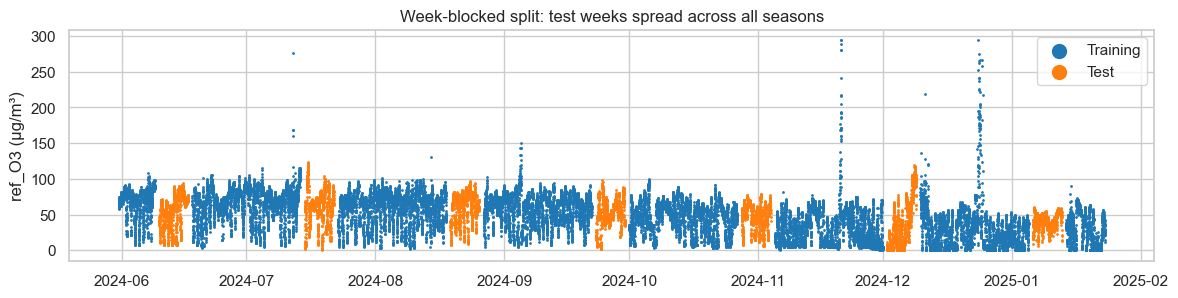

In [24]:
# Visualise the split over time
fig, ax = plt.subplots(figsize=(14, 3))
ax.scatter(X_train.index, y_train, s=1, label="Training", color="tab:blue")
ax.scatter(X_test.index, y_test, s=1, label="Test", color="tab:orange")
ax.set_title("Week-blocked split: test weeks spread across all seasons")
ax.set_ylabel("ref_O3 (µg/m³)")
ax.legend(markerscale=10, loc="upper right")
plt.show()

**Result:** 25,007 training rows and 7,056 test rows (~22 %). The test weeks cover every
season from June to January, and their target distribution is similar to training
(median 51 vs 53 µg/m³), so the test is fair and representative. 2,016 rows next to test
weeks were left out of training to prevent leakage across the boundaries.

### 4.4 Preprocessing pipeline: imputation and scaling
Two preprocessing steps are placed inside an sklearn **`Pipeline`** (Lecture 3, Seminar 4), so
they are **learned from the training data only** and then applied unchanged to the test data:
1. **`SimpleImputer(strategy="median")`** fills the 119 missing `n1_O3` values. The median is
   used rather than the mean because the inputs are skewed (Section 3.1).
2. **`StandardScaler`** rescales every feature to mean 0 and standard deviation 1. This is
   needed for **Linear Regression and KNN**: KNN measures distances, so a feature with large
   numbers (CO2 ≈ 800) would otherwise dominate one with small numbers (VOC ≈ 0.1). It is
   **not needed for tree-based models** (Random Forest, XGBoost), which split on one feature
   at a time and are unaffected by scale (Seminar 7).

Below, the scaling pipeline is fitted on the training set to show its effect.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocess_scaled = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Fit on TRAINING data only, then apply to both sets
demo = preprocess_scaled.fit(X_train)
print("Median used to fill missing n1_O3 (learned from training only):",
      round(demo.named_steps["impute"].statistics_[FEATURES.index("n1_O3")], 2))

X_train_scaled = pd.DataFrame(demo.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled  = pd.DataFrame(demo.transform(X_test),  columns=FEATURES, index=X_test.index)

pd.DataFrame({
    "train mean before": X_train.mean(), "train std before": X_train.std(),
    "train mean after": X_train_scaled.mean(), "train std after": X_train_scaled.std(),
    "test mean after": X_test_scaled.mean(),
}).round(2)

Median used to fill missing n1_O3 (learned from training only): 43.97


,train mean before,train std before,train mean after,train std after,test mean after
n1_Temp,15.350,7.490,0.000,1.000,0.070
n1_HR,95.930,19.560,0.000,1.000,-0.060
n1_PM2_5,19.360,6.340,-0.000,1.000,0.100
n1_VOC,0.090,0.420,0.000,1.000,-0.100
n1_CH2O,0.020,0.000,-0.000,1.000,-0.080
n1_CO2,804.730,53.880,0.000,1.000,-0.100
n1_O3,56.200,26.350,0.000,1.000,-0.030
o3_at_floor,0.310,0.460,-0.000,1.000,-0.050
hour_sin,0.000,0.710,0.000,1.000,-0.000
hour_cos,-0.000,0.710,-0.000,1.000,0.000


The test means after scaling are close to, but not exactly, 0. This is expected and correct:
the scaler used the **training** mean and std, and the test data was never seen during
fitting. If the test means were exactly 0, it would mean the scaler had been fitted on the
test data, which is leakage.

### 4.5 Checking the engineered features
Before modelling, we check whether the new features help, and test two more candidate
features. Each feature set is scored with a default **XGBoost** model (Seminar 7) using
**5-fold cross-validation grouped by week** (`GroupKFold`) on the **training set only**, so the
test set stays untouched. Lower MAE (mean absolute error, µg/m³) is better.
- **Month (sine/cosine):** could capture the seasonal trend from Section 3.4.
- **1-hour rolling mean and 1-hour lag of `n1_O3`:** could smooth the noisy sensor.

In [26]:
from sklearn.model_selection import GroupKFold, cross_val_score
from xgboost import XGBRegressor

cv = GroupKFold(n_splits=5)      # whole weeks stay together in each fold

def cv_mae(X):
    """Mean absolute error of a default XGBoost model, 5-fold CV grouped by week."""
    pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("model", XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
    scores = cross_val_score(pipe, X, y_train, groups=groups_train, cv=cv,
                             scoring="neg_mean_absolute_error")
    return -scores.mean(), scores.std()

idx = X_train.index
o3_clean = df["n1_O3"].where(df["n1_O3"] <= 200)     # sensor spikes removed

# Candidate 1: month on a circle
X_month = X_train.copy()
X_month["month_sin"] = np.sin(2 * np.pi * idx.month / 12)
X_month["month_cos"] = np.cos(2 * np.pi * idx.month / 12)

# Candidate 2: 1-hour (6 × 10 min) rolling mean and lag, using only PAST values
X_lag = X_train.copy()
X_lag["n1_O3_roll1h"] = o3_clean.rolling(6, min_periods=1).mean().loc[idx]
X_lag["n1_O3_lag1h"]  = o3_clean.shift(6).loc[idx]

experiments = {
    "Raw sensor inputs only":        cv_mae(X_train[INPUTS]),
    "+ floor flag + hour (chosen)":  cv_mae(X_train),
    "+ month":                       cv_mae(X_month),
    "+ 1-hour rolling mean and lag": cv_mae(X_lag),
}
pd.DataFrame(experiments, index=["CV MAE", "std"]).T.round(2)

,CV MAE,std
Raw sensor inputs only,13.820,2.100
+ floor flag + hour (chosen),12.950,1.510
+ month,12.920,1.240
+ 1-hour rolling mean and lag,12.950,1.390


**Feature decisions**
- **Floor flag + hour: kept.** They reduce the error from 13.82 to 12.95 µg/m³ and make the
  results more stable across folds (std 2.10 → 1.51), the clearest improvement of all.
- **Month: rejected.** It changes the error by only 0.03 µg/m³ (12.95 → 12.92), far smaller than
  the variation between folds (std ≈ 1.2–1.5), so the gain is not reliable. The data also covers
  only 8 months, so a model using month cannot generalise to months it has never seen
  (February–April), and temperature already captures most of the seasonal effect.
- **Rolling mean and lag: rejected.** They give no improvement at all (12.95 → 12.95). They
  would also require a full hour of past readings for every prediction, which complicates
  real use and the Streamlit app.

### 4.6 Summary of Part C
| Step | Result |
|---|---|
| Rows | 34,141 → 34,079 (62 target errors removed) |
| Features | 10: 7 node-1 sensor readings + floor flag + hour (sine, cosine) |
| Missing values | 119 sensor spikes → median imputation inside the pipeline |
| Split | 25,007 training / 7,056 test rows, 7 test weeks across all seasons, 1-day gap |
| Scaling | StandardScaler inside the pipeline, for Linear Regression and KNN only |
| Validation for Part D | 5-fold GroupKFold by week, on training data only |

# Part D — Modelling

## 5. Model training and hyperparameter tuning

### 5.1 Approach
Four regression models are compared, from simple to complex (Lectures 4–6, Seminars 5–7):

| # | Model | Why it is included |
|---|---|---|
| 1 | Linear Regression | Simple, interpretable baseline; assumes a straight-line relationship |
| 2 | K-Nearest Neighbours | Non-linear; predicts from the most similar past situations |
| 3 | Random Forest | Ensemble of decision trees (bagging); captures non-linear effects such as the sensor floor |
| 4 | XGBoost | Ensemble of trees built one after another (boosting); often the strongest on tabular data |

**Same rules for every model (a fair comparison):**
- Trained and tuned on the **training weeks only**; the test weeks are not touched until Part E.
- Hyperparameters chosen with **`GridSearchCV`** (Seminar 6), using **5-fold `GroupKFold` by week**,
  instead of the seminars' shuffled `KFold`, which would leak near-identical rows between folds.
- Preprocessing (imputation and, where needed, scaling) is **inside the pipeline**, so it is
  re-learned within each fold.
- **Metrics:** MAE (main metric: average error in µg/m³, robust to the remaining outliers),
  RMSE (punishes large errors more) and R² (share of variation explained).

In [27]:
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import time

cv = GroupKFold(n_splits=5)
SCORING = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

cv_results = {}     # cross-validation scores of each model's best settings
best_models = {}    # each model refitted on all training data with its best settings

def tune(name, pipeline, param_grid):
    """Grid search with week-grouped CV; stores and prints the best result."""
    start = time.time()
    search = GridSearchCV(pipeline, param_grid, cv=cv, scoring=SCORING,
                          refit="MAE", n_jobs=1)
    search.fit(X_train, y_train, groups=groups_train)

    i, r = search.best_index_, search.cv_results_
    cv_results[name] = {"CV MAE": -r["mean_test_MAE"][i],
                        "CV MAE std": r["std_test_MAE"][i],
                        "CV RMSE": -r["mean_test_RMSE"][i],
                        "CV R2": r["mean_test_R2"][i]}
    best_models[name] = search.best_estimator_

    print(f"{name} — best settings: {search.best_params_}  ({time.time() - start:.0f} s)")
    print({k: round(float(v), 2) for k, v in cv_results[name].items()})
    return search

### 5.2 Model 1: Linear Regression
**How it works:** fits a weighted sum of the inputs, ŷ = b₀ + b₁x₁ + … + bₙxₙ, choosing the
weights that minimise the squared error (Lecture 4).

**Assumptions and biases:** assumes each input affects ozone in a **straight line** and
independently of the others. From the EDA we know this is not true. The sensor floor and the
daily cycle are non-linear, and the PM sensors are collinear. So this model is expected to
**underfit** (high bias). It serves as the simple baseline the other models must beat.

**Hyperparameters:** none to tune. Inputs are **scaled** so the coefficients can be compared
with each other.

Linear Regression — best settings: {}  (0 s)
{'CV MAE': 13.49, 'CV MAE std': 1.01, 'CV RMSE': 19.42, 'CV R2': 0.5}


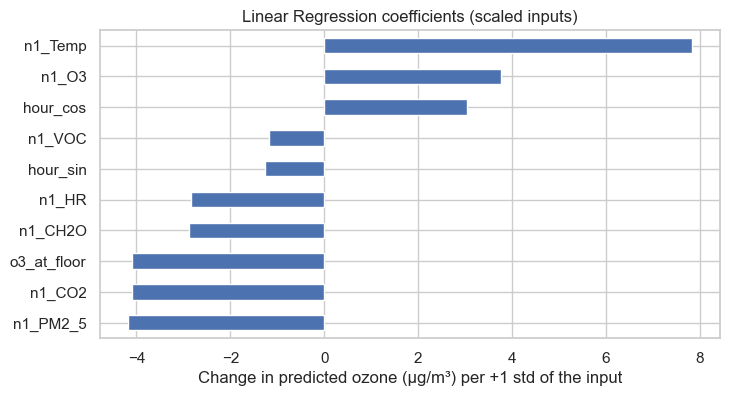

In [28]:
lin_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])
tune("Linear Regression", lin_pipe, {})

# Coefficients: effect of +1 standard deviation of each input on predicted ozone (µg/m³)
coefs = pd.Series(best_models["Linear Regression"].named_steps["model"].coef_, index=FEATURES)
coefs.sort_values().plot(kind="barh", figsize=(8, 4), title="Linear Regression coefficients (scaled inputs)")
plt.xlabel("Change in predicted ozone (µg/m³) per +1 std of the input")
plt.show()

**Result:** CV MAE **13.49 µg/m³** (± 1.01 across folds), RMSE 19.42, R² **0.50**. The linear
model explains about half of the variation in real ozone.

**What the coefficients show** (scaled inputs, so bar lengths are comparable):
- **Temperature has the largest positive effect** (+7.8 per std): warm conditions mean sunlight
  and ozone formation, matching the EDA correlation (Section 3.5).
- **The raw ozone sensor is only second** (+3.8): on its own it is a weak guide to real ozone.
- **`o3_at_floor` is negative** (−4.1): when the sensor is stuck at its minimum, real ozone
  tends to be even lower than the reading suggests, which is exactly what the flag was designed
  to capture (Section 3.3).
- **CO2 and PM2.5 are negative** (about −4): high values indicate traffic emissions and still
  air, conditions under which ozone is destroyed (Section 3.4).

**Limitation:** a straight-line model cannot represent the sensor floor or the daily cycle
properly (both are non-linear), so it underfits. This sets the baseline for the non-linear
models below.

### 5.3 Model 2: K-Nearest Neighbours (KNN) regression
**How it works:** to predict a new row, KNN finds the **K most similar rows** in the training
data (by Euclidean distance between their feature values) and averages their ozone values
(Lecture 5, Seminar 6). It learns no formula, so it is called a "lazy" learner.

**Assumptions and biases:** assumes that similar sensor conditions mean similar real ozone.
Because it uses distances, it **requires scaled inputs**: otherwise CO2 (≈ 800) would dominate
VOC (≈ 0.1) (Section 4.4). It can capture non-linear patterns such as the sensor floor, but
becomes slow with large data and weak with many irrelevant features.

**Hyperparameters tuned:**
- `n_neighbors` (K): small K follows noise (**overfitting**, high variance); large K averages
  too much (**underfitting**, high bias). Tried 15–400.
- `weights`: `uniform` (all K neighbours count equally) or `distance` (closer neighbours count more).

KNN — best settings: {'model__n_neighbors': 100, 'model__weights': 'distance'}  (7 s)
{'CV MAE': 11.89, 'CV MAE std': 0.84, 'CV RMSE': 17.83, 'CV R2': 0.58}


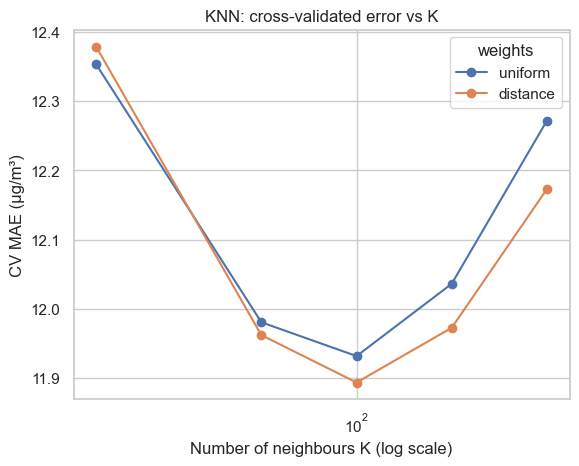

In [29]:
knn_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_jobs=-1)),
])
knn_grid = {
    "model__n_neighbors": [15, 50, 100, 200, 400],
    "model__weights": ["uniform", "distance"],
}
knn_search = tune("KNN", knn_pipe, knn_grid)

# How does the error change with K? (the bias-variance trade-off)
res = pd.DataFrame(knn_search.cv_results_)
for w in ["uniform", "distance"]:
    sub = res[res["param_model__weights"] == w]
    plt.plot(sub["param_model__n_neighbors"], -sub["mean_test_MAE"], marker="o", label=w)
plt.xscale("log")
plt.xlabel("Number of neighbours K (log scale)")
plt.ylabel("CV MAE (µg/m³)")
plt.title("KNN: cross-validated error vs K")
plt.legend(title="weights")
plt.show()

**Result:** best settings **K = 100** with **distance** weighting. CV MAE **11.89 µg/m³**
(± 0.84), RMSE 17.83, R² **0.58**. This is clearly better than Linear Regression (MAE 13.49,
R² 0.50), confirming that the relationship between the sensor readings and real ozone is
non-linear.

**The K chart shows the bias–variance trade-off** (Lecture 5):
- **Small K (15):** error ~12.4. Each prediction copies a few neighbours, including their
  noise (**overfitting**, high variance).
- **K = 100:** lowest error. Enough neighbours to average out noise.
- **Large K (400):** error rises again. Predictions average over too many dissimilar
  situations (**underfitting**, high bias).
- **Distance weighting** is slightly better than uniform at every K, because closer (more
  similar) situations are more informative.

KNN also has the **most stable results across folds** so far (std 0.84).

### 5.4 Model 3: Random Forest
**How it works:** builds many **decision trees** (Lecture 6), each on a random bootstrap
sample of the rows and considering a random subset of features at each split (**bagging**).
Each tree splits the data with yes/no questions (e.g. "is `o3_at_floor` = 1?"), choosing the
split that most reduces the variance of ozone. The forest's prediction is the **average of
all trees**, which cancels out much of the individual trees' noise.

**Assumptions and biases:** makes no assumption about linearity or distributions, and is not
affected by feature scale, so **no scaling is needed** (Seminar 7). It handles thresholds such
as the sensor floor naturally. A single deep tree overfits badly; averaging many trees reduces
this variance. It cannot predict values outside the range seen in training.

**Hyperparameters tuned** (100 trees in each forest):
- `max_depth`: how deep each tree can grow (10, or unlimited). Deeper trees learn more detail
  but risk overfitting.
- `min_samples_leaf`: minimum rows in each final leaf (5, 20, 50). Larger values smooth the
  predictions (a form of **pruning**, Seminar 7).
- `max_features`: share of features considered at each split (all, or half). Using half makes
  the trees more different from each other, which helps the average.

Random Forest — best settings: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 20}  (31 s)
{'CV MAE': 11.5, 'CV MAE std': 0.95, 'CV RMSE': 17.35, 'CV R2': 0.6}


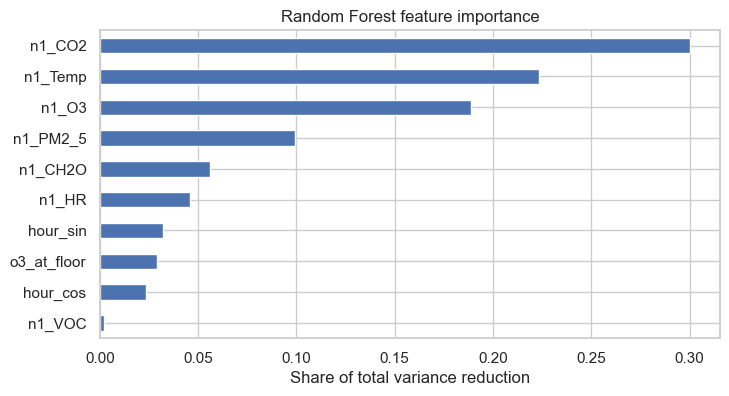

In [30]:
rf_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_grid = {
    "model__max_depth": [10, None],
    "model__min_samples_leaf": [5, 20, 50],
    "model__max_features": [1.0, 0.5],
}
rf_search = tune("Random Forest", rf_pipe, rf_grid)

# Which features does the forest rely on most?
importances = pd.Series(best_models["Random Forest"].named_steps["model"].feature_importances_,
                        index=FEATURES).sort_values()
importances.plot(kind="barh", figsize=(8, 4), title="Random Forest feature importance")
plt.xlabel("Share of total variance reduction")
plt.show()

**Result:** best settings: unlimited depth, `max_features` = 0.5, `min_samples_leaf` = 20.
CV MAE **11.50 µg/m³** (± 0.95), RMSE 17.35, R² **0.60**, the best model so far (KNN 11.89,
Linear Regression 13.49).

**Tuning:** the best forest uses fully grown trees, but with at least 20 rows per leaf. The
leaf limit smooths predictions and prevents overfitting to noisy 10-minute readings. Using
half of the features at each split makes the trees more diverse, which improves the average.

**Feature importance** tells a different story from the linear coefficients:
- **CO2 is the most important feature** (~30 %), followed by temperature (~22 %) and the raw
  ozone sensor (~19 %). CO2 reflects traffic emissions and how well the air is mixed, both of
  which control how much ozone is destroyed near the ground.
- **`o3_at_floor` has low importance here** (~3 %), although it was strong in the linear model.
  Trees can learn the floor directly from `n1_O3` with one split at 39.246, so the flag is
  redundant for them. It mainly helps the linear model.
- **Hour features are low** (2–3 % each) because temperature and CO2 already follow the
  daily cycle.
- *Caveat:* this importance measure tends to favour continuous features with many possible
  split points, so it is a guide, not proof.

### 5.5 Model 4: XGBoost (gradient boosting)
**How it works:** also an ensemble of decision trees, but built **one after another**
(**boosting**, Lecture 6, Seminar 7). Each new small tree is trained to correct the errors
left by all previous trees, and its contribution is scaled down by a **learning rate**.

**Assumptions and biases:** like Random Forest, it needs no scaling and handles non-linear
effects. Because each tree focuses on the remaining errors, boosting can reach lower bias
than bagging, but it can also **overfit noise** if trees are too deep or too many, so it
must be regularised.

**Hyperparameters tuned** (300 trees, each on a random 80 % of rows):
- `max_depth` (3, 5, 7): size of each tree; deeper trees capture more complex interactions.
- `learning_rate` (0.03, 0.1): how much each tree contributes; smaller is slower but safer.
- `min_child_weight` (1, 50): minimum amount of data in a leaf; larger values regularise.

In [31]:
xgb_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", XGBRegressor(n_estimators=300, subsample=0.8,
                           random_state=RANDOM_STATE, n_jobs=-1)),
])
xgb_grid = {
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.1],
    "model__min_child_weight": [1, 50],
}
xgb_search = tune("XGBoost", xgb_pipe, xgb_grid)

XGBoost — best settings: {'model__learning_rate': 0.03, 'model__max_depth': 5, 'model__min_child_weight': 50}  (10 s)
{'CV MAE': 11.88, 'CV MAE std': 1.22, 'CV RMSE': 18.21, 'CV R2': 0.55}


,CV MAE,CV MAE std,CV RMSE,CV R2
Random Forest,11.500,0.950,17.350,0.600
XGBoost,11.880,1.220,18.210,0.550
KNN,11.890,0.840,17.830,0.580
Linear Regression,13.490,1.010,19.420,0.500


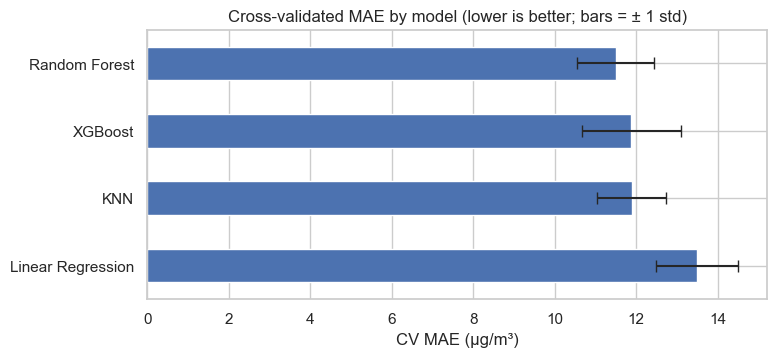

In [32]:
cv_table = pd.DataFrame(cv_results).T.sort_values("CV MAE").round(2)
display(cv_table)

cv_table["CV MAE"].plot(kind="barh", xerr=cv_table["CV MAE std"], figsize=(8, 3.5), capsize=4,
                        title="Cross-validated MAE by model (lower is better; bars = ± 1 std)")
plt.xlabel("CV MAE (µg/m³)")
plt.gca().invert_yaxis()
plt.show()

**Result:** best settings: `learning_rate` = 0.03, `max_depth` = 5, `min_child_weight` = 50.
CV MAE **11.88 µg/m³** (± 1.22), RMSE 18.21, R² **0.55**.

**Tuning:** the search chose the **more cautious options**: the smaller learning rate, medium-depth
trees and the stronger leaf limit (50). This shows that the main risk on this data is
**overfitting to noisy 10-minute readings**, so heavy regularisation works best.

XGBoost did **not** beat Random Forest here, although boosting is often the strongest method on
tabular data. A likely reason is that the targets are very noisy: boosting keeps fitting the
remaining errors, which are mostly noise here, while bagging averages noise out.

**Comparison**
- **All three non-linear models clearly beat Linear Regression** (MAE ~11.5–11.9 vs 13.49),
  confirming the non-linear relationships found in the EDA (sensor floor, daily cycle).
- **Random Forest is best on all three metrics** (lowest MAE and RMSE, highest R²).
- **However, the differences between the top three are small**: 0.38–0.39 µg/m³, smaller than
  one standard deviation across folds (≈ 0.8–1.2), and their error bars overlap. So the ranking
  of the top three is **not certain**; on different weeks, a different model could win.
- **KNN is the most consistent** across folds (std 0.84), and XGBoost the least (1.22).

**Final model choice: Random Forest.** It has the best average score on every metric, a
moderate fold-to-fold variation, and gives feature importances that help explain its
predictions. The choice is made **on the cross-validation results only**, before looking at the
test set, so the test score in Part E remains an honest, unbiased estimate.

### 5.7 Summary of Part D
| Model | Best settings | CV MAE (µg/m³) | CV R² |
|---|---|---|---|
| Random Forest **(chosen)** | unlimited depth, min 20 rows per leaf, half the features per split | **11.50 ± 0.95** | **0.60** |
| XGBoost | learning rate 0.03, depth 5, min child weight 50 | 11.88 ± 1.22 | 0.55 |
| KNN | K = 100, distance weighting | 11.89 ± 0.84 | 0.58 |
| Linear Regression | — | 13.49 ± 1.01 | 0.50 |

**Next (Part E):** all models are evaluated **once** on the 7 held-out test weeks and compared
with the **raw low-cost sensor**, the baseline the project set out to beat.

# Part E — Evaluation

## 6. Model evaluation on the held-out test weeks

### 6.1 Test-set performance
Every tuned model is now evaluated **once** on the 7 test weeks (7,056 rows), which were not used
for any training, tuning or model selection. The models are compared with the **baseline the
project set out to beat: the raw low-cost ozone reading itself**, used with no correction.

Metrics (Lecture 5, Seminar 6):
- **MAE**: average size of the error in µg/m³, easy to interpret and robust to outliers (main metric);
- **RMSE**: like MAE but punishes large errors more, so it matters when big misses are costly;
- **R²**: share of the variation in real ozone that the predictions explain (1 = perfect, 0 = no
  better than always predicting the average, negative = worse than that).

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def scores(y_true, y_pred):
    """MAE, RMSE and R² for one set of predictions."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}

# Baseline: the raw low-cost sensor reading (spikes filled with the training median)
raw_sensor = X_test["n1_O3"].fillna(X_train["n1_O3"].median())
test_pred = {"Raw sensor (no model)": raw_sensor.values}
test_results = {"Raw sensor (no model)": scores(y_test, raw_sensor)}

# Each tuned model predicts the test weeks
for name, model in best_models.items():
    test_pred[name] = model.predict(X_test)
    test_results[name] = scores(y_test, test_pred[name])

test_table = pd.DataFrame(test_results).T
test_table["CV MAE"] = pd.Series({k: v["CV MAE"] for k, v in cv_results.items()})
test_table = test_table.sort_values("MAE").round(2)
display(test_table)

base_mae = test_table.loc["Raw sensor (no model)", "MAE"]
rf_mae = test_table.loc["Random Forest", "MAE"]
print(f"Random Forest reduces the raw sensor's error by {(1 - rf_mae / base_mae) * 100:.0f} %")

,MAE,RMSE,R2,CV MAE
XGBoost,10.520,14.030,0.660,11.880
Random Forest,10.620,14.110,0.650,11.500
KNN,11.060,14.980,0.610,11.890
Linear Regression,12.650,16.740,0.510,13.490
Raw sensor (no model),19.330,25.680,-0.150,NaN


Random Forest reduces the raw sensor's error by 45 %


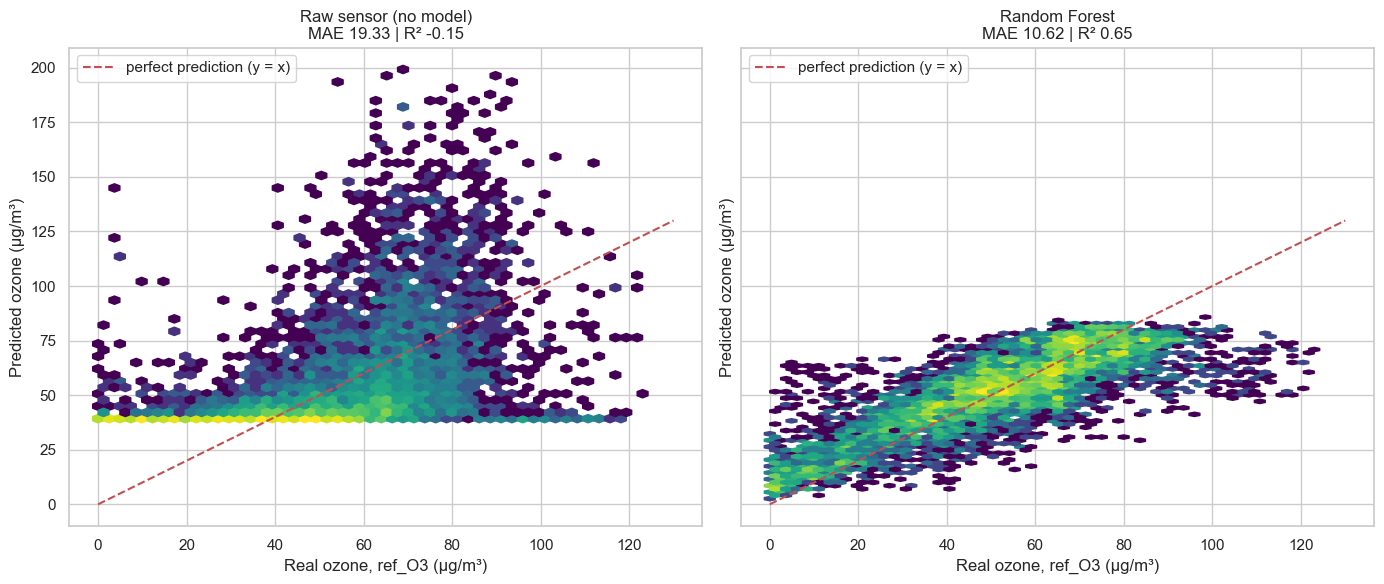

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, name in zip(axes, ["Raw sensor (no model)", "Random Forest"]):
    ax.hexbin(y_test, test_pred[name], gridsize=50, bins="log", cmap="viridis")
    ax.plot([0, 130], [0, 130], "r--", label="perfect prediction (y = x)")
    m = test_results[name]
    ax.set_title(f"{name}\nMAE {m['MAE']:.2f} | R² {m['R2']:.2f}")
    ax.set_xlabel("Real ozone, ref_O3 (µg/m³)")
    ax.set_ylabel("Predicted ozone (µg/m³)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Results on the held-out test weeks**

| | MAE | RMSE | R² |
|---|---|---|---|
| Raw low-cost sensor (no model) | 19.33 | 25.68 | **−0.15** |
| **Random Forest (chosen model)** | **10.62** | **14.11** | **0.65** |

- **The project goal is achieved:** the Random Forest reduces the raw sensor's average error by
  **45 %** (19.33 → 10.62 µg/m³) and raises R² from −0.15 to 0.65.
- **The raw sensor is worse than useless as a direct reading:** a negative R² means it is less
  accurate than simply predicting the average ozone level every time. The left plot shows why:
  the horizontal band at ~39 µg/m³ is the **sensor floor** (Section 3.3), where the sensor shows
  39 while real ozone is anywhere from 0 to 100, and many readings are far too high.
- **All four models beat the raw sensor by a wide margin**, and the ranking matches cross-validation:
  the three non-linear models are close together (MAE 10.52–11.06), and Linear Regression is clearly last.
- **XGBoost is marginally ahead of Random Forest on the test set** (10.52 vs 10.62). This difference
  is very small and consistent with the cross-validation finding that the top models are statistically
  tied. The final model is **not changed** based on the test result: selecting a model using the test
  set would make the test score optimistically biased.
- **Test errors are lower than CV errors** for every model (e.g. Random Forest 10.62 vs 11.50). The
  test weeks contain fewer extreme ozone values (maximum 123 vs 294 µg/m³ in training; std 23.9 vs
  27.5, Section 4.3), so they are slightly easier to predict. The CV score is the more conservative
  estimate of real-world performance.

**Limitation visible in the right plot:** the Random Forest **compresses the range**. It overestimates
very low ozone (< 20) and underestimates high ozone (> 90). Averaging over many trees pulls predictions
towards the middle, and high-ozone situations are rare in the training data. This matters because
**high ozone is the case people most need to know about** for health warnings.

### 6.2 Error analysis
To understand *when* the model works and when it fails, the absolute errors of the raw sensor and the
Random Forest are compared by **hour of day**, by **test week** (season), and by whether the sensor was
at its **floor**.

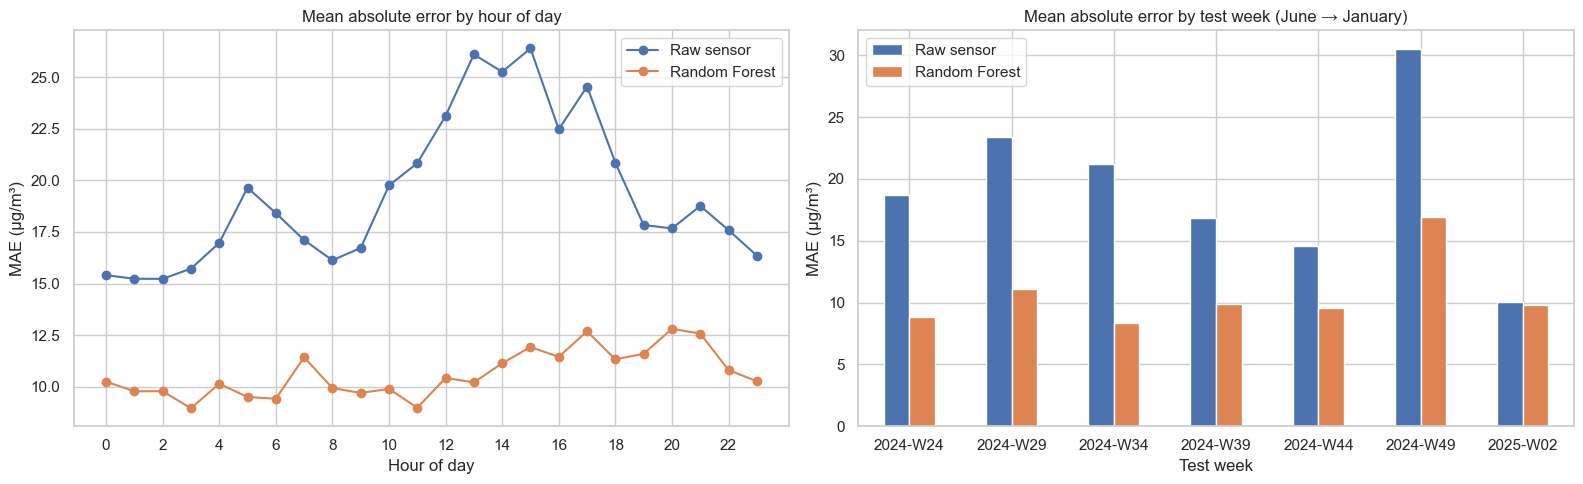

                     Raw sensor  Random Forest
o3_at_floor                                   
Sensor at floor          19.400         10.970
Sensor not at floor      19.310         10.490


In [35]:
# Absolute error of each prediction on the test weeks
errors = pd.DataFrame({
    "Raw sensor": (raw_sensor - y_test).abs(),
    "Random Forest": (test_pred["Random Forest"] - y_test).abs(),
})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

errors.groupby(errors.index.hour).mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Mean absolute error by hour of day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MAE (µg/m³)")
axes[0].set_xticks(range(0, 24, 2))

errors.groupby(data.loc[is_test, "week"]).mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean absolute error by test week (June → January)")
axes[1].set_xlabel("Test week")
axes[1].set_ylabel("MAE (µg/m³)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Error when the sensor is at its floor vs not
at_floor = X_test["o3_at_floor"].map({1: "Sensor at floor", 0: "Sensor not at floor"})
print(errors.groupby(at_floor).mean().round(2))

**Findings**
- **By hour of day:** the raw sensor's errors are largest in the **afternoon** (~25 µg/m³ at 13:00–17:00)
  and smallest at night (~15). At high ozone the cheap sensor is noisy and often overshoots. The Random
  Forest keeps its error at **9–13 µg/m³ at every hour**, so the correction helps most exactly when ozone
  peaks. This refines the EDA (Section 3.4): the floor is the most *visible* problem, but in absolute terms
  the largest raw-sensor errors happen in the afternoon.
- **By week:** the model beats the raw sensor in **every test week**, but by very different amounts:
  - largest gains in summer (e.g. 2024-W34: 21.0 → 8.3);
  - **worst week: 2024-W49 (early December)**, MAE 16.8 (raw 30.3). This week contains unusual ozone
    spikes (up to ~120 µg/m³, Section 4.3) during winter, a combination rarely seen in training, so the
    model cannot reproduce them (the range-compression limitation in Section 6.1);
  - **smallest gain: 2025-W02 (January)**, 9.8 vs 10.0. In mid-winter real ozone is often close to the
    sensor's floor value (~39), so the raw reading happens to be roughly right and there is little to correct.
- **Sensor floor:** the Random Forest's error is nearly the same whether or not the sensor is at its floor
  (10.97 vs 10.49 µg/m³), so it has learned to correct the floor readings almost as well as normal ones.

**Conclusion:** the calibration is reliable across hours and most of the year, but **weaker for rare
situations not well represented in training** (winter spikes). More data covering a full year, and other
winters, would be the most effective improvement.

### 6.3 Saving the final model
The chosen **Random Forest pipeline** (imputation + model) is saved with `joblib`, so the Streamlit app
can load it and make predictions without retraining. The metrics tables and test-set predictions are also
saved for the app's evaluation dashboard. The saved model is the one trained on the training weeks only,
so it matches all the scores reported above.

In [36]:
import joblib
import json

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# 1. The final model (the whole pipeline, so imputation is included)
model_path = MODEL_DIR / "random_forest.joblib"
joblib.dump(best_models["Random Forest"], model_path, compress=3)
print(f"Model saved: {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# 2. Settings the app needs to build features in the same way
model_info = {
    "features": FEATURES,
    "sensor_floor": FLOOR,
    "target": TARGET,
    "best_params": {k.replace("model__", ""): v
                    for k, v in rf_search.best_params_.items()},
}
with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

# 3. Results for the evaluation dashboard
cv_table.to_csv(MODEL_DIR / "cv_results.csv")
test_table.to_csv(MODEL_DIR / "test_results.csv")
pd.DataFrame({"real_O3": y_test,
              "raw_sensor": raw_sensor,
              "random_forest": test_pred["Random Forest"]}).to_csv(MODEL_DIR / "test_predictions.csv")

print("Saved files:", sorted(p.name for p in MODEL_DIR.iterdir()))

Model saved: ../models/random_forest.joblib (3.2 MB)
Saved files: ['cv_results.csv', 'model_info.json', 'random_forest.joblib', 'test_predictions.csv', 'test_results.csv']


## 7. Conclusion

**Question:** can machine learning turn readings from a low-cost sensor into reliable ozone values?

**Answer: yes, largely.** Using only the cheap sensor's readings and the time of day, the Random Forest
predicts the official station's ozone with an MAE of **10.62 µg/m³** and R² of **0.65** on 7 unseen test
weeks, compared with MAE 19.33 and R² −0.15 for the raw sensor: a **45 % reduction in error**.

**Key findings**
1. The raw sensor has a **detection floor** at 39.246 µg/m³ and large afternoon errors; it is less accurate
   than simply predicting the average.
2. **Non-linear models** (Random Forest, XGBoost, KNN) clearly beat Linear Regression, and the three
   performed within one standard deviation of each other.
3. **Temperature and CO2**, not only the ozone sensor itself, carry most of the information, because ozone
   depends on sunlight and on how the air is mixed.
4. **Week-blocked validation** gave honest, slightly conservative estimates (CV MAE 11.50 vs test 10.62).

**Limitations**
- Only 8 months of data from **one location**; the model has never seen February–April or another site.
- It **underestimates high ozone**, the most important case for health warnings.
- Node 2's data was partly a copy of node 1 and largely stuck, so the model relies on one sensor node.

**Future work**
- Collect a full year, ideally at several stations, and test on a different location.
- Give more weight to high-ozone situations (e.g. sample weighting) to reduce range compression.
- Re-calibrate periodically, since low-cost sensors drift with age.